In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os, os.path
import numpy as np
import warnings
import re
from sklearn.decomposition import PCA
from pathlib import Path
from scipy import stats
from scipy.integrate import simpson
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneOut

warnings.filterwarnings("ignore")

BASE_DIR = Path("OSA_Measurements")

In [ ]:
def mWtoDBm(val):
    return 10*np.log10(val)

def load_wad_file(filepath):
    try:
        with open(filepath, 'r') as f:
            lines = f.readlines()
        data_start_idx = None
        for idx, line in enumerate(lines):
            if line.strip() == "Data:":
                data_start_idx = idx + 2  
                break
        
        if data_start_idx is None:
            print(f"Warning: Could not find 'Data:' section in {filepath}")
            return None
        data_lines = lines[data_start_idx:]
        frequencies = []
        wavelengths = []
        powers = []
        
        for line in data_lines:
            line = line.strip()
            if not line:  
                continue
            try:
                parts = line.split()
                if len(parts) >= 3:
                    frequencies.append(float(parts[0]))
                    wavelengths.append(float(parts[1]))
                    powers.append(float(parts[2]))
            except ValueError:
                continue
        
        # Create dataframe
        df = pd.DataFrame({
            'Frequency [THz]': frequencies,
            'Wavelength [nm]': wavelengths,
            'Absolute Power [mW]': powers
        })

        return df
    
    except Exception as e:
        print(f"Error loading {filepath}: {e}")
        return None
    
def fill_nan_with_neighbors(df):
    df_filled = df.copy()
    feature_cols = [col for col in df.columns if col not in ['day', 'depth_cm', 'label']]
    for idx in range(len(df_filled)):
        if df_filled.iloc[idx][feature_cols].isna().any():
            for col in feature_cols:
                if pd.isna(df_filled.iloc[idx][col]):
                    before_val = df_filled.iloc[idx-1][col] if idx > 0 else None
                    after_val = df_filled.iloc[idx+1][col] if idx < len(df_filled)-1 else None
                    
                    if before_val is not None and after_val is not None and not pd.isna(before_val) and not pd.isna(after_val):
                        df_filled.loc[df_filled.index[idx], col] = (before_val + after_val) / 2
                    elif before_val is not None and not pd.isna(before_val):
                        df_filled.loc[df_filled.index[idx], col] = before_val
                    elif after_val is not None and not pd.isna(after_val):
                        df_filled.loc[df_filled.index[idx], col] = after_val
    return df_filled


def extract_wavelengths_at_power(sensor_data, fiber_id, expected_wavelengths, target_power=-55.0, tolerance=1.0, smoothing_window=1, subtract_day0=False):
    fiber_base = fiber_id.split('_')[0]
    
    if fiber_base not in expected_wavelengths:
        raise ValueError(f"Fiber {fiber_base} not found in expected_wavelengths")
    
    expected_wl = expected_wavelengths[fiber_base]

    if fiber_id.endswith('_V6_2'):
            position_mapping = peak_to_position_V6.get(fiber_base, {})
    if fiber_id.endswith('_V6'):
        position_mapping = peak_to_position_V6.get(fiber_base, {})
    elif fiber_id.endswith('_V5'):
        position_mapping = peak_to_position_V5.get(fiber_base, {})
    elif fiber_id.endswith('_V4'):
        position_mapping = peak_to_position_V4.get(fiber_base, {})
    elif fiber_id.endswith('_V3'):
        position_mapping = peak_to_position_V3.get(fiber_base, {})
    elif fiber_id.endswith('_V2'):
        position_mapping = peak_to_position_V2.get(fiber_base, {})
    else:
        position_mapping = peak_to_position_V3.get(fiber_base, {})
    
    results = []
    wavelengths = sensor_data['Wavelength [nm]'].values
    
    for col in sensor_data.columns:
        if col == 'Wavelength [nm]':
            continue
        
        match = re.match(r'D(\d+)', col)
        day_number = int(match.group(1)) if match else None
        
        power_values = sensor_data[col].values
        
        if smoothing_window > 1:
            window = np.ones(smoothing_window) / smoothing_window
            power_values = np.convolve(power_values, window, mode='same')

        row_data = {'day': day_number}
        
        for peak_idx, expected_wl_value in enumerate(expected_wl):
            closest_idx = np.argmin(np.abs(wavelengths - expected_wl_value))
            search_range = 200  
            start_idx = max(0, closest_idx - search_range)
            end_idx = min(len(wavelengths), closest_idx + search_range)
            
            search_wl = wavelengths[start_idx:end_idx]
            search_power = power_values[start_idx:end_idx]
            
            peak_center_idx = np.argmax(search_power)
            peak_center_wl = search_wl[peak_center_idx]
            peak_center_power = search_power[peak_center_idx]
            
            trailing_edge_mask = search_wl >= peak_center_wl
            trailing_wl = search_wl[trailing_edge_mask]
            trailing_power = search_power[trailing_edge_mask]
            
            if len(trailing_wl) == 0:
                position = position_mapping.get(peak_idx, f'peak_{peak_idx}')
                row_data[position] = np.nan
                continue
            
            power_diffs = np.abs(trailing_power - target_power)
            close_indices = np.where(power_diffs <= tolerance)[0]
            
            if len(close_indices) > 0:
                first_crossing_idx = close_indices[0]
                wavelength_at_target = trailing_wl[first_crossing_idx]
                position = position_mapping.get(peak_idx, f'peak_{peak_idx}')
                row_data[position] = wavelength_at_target
            else:
                try:
                    if len(trailing_wl) > 2 and target_power < peak_center_power:
                        f_interp = interp1d(trailing_power, trailing_wl, kind='linear', 
                                          fill_value='extrapolate', bounds_error=False)
                        wavelength_at_target = f_interp(target_power)
                        
                        if wavelength_at_target >= peak_center_wl:
                            position = position_mapping.get(peak_idx, f'peak_{peak_idx}')
                            row_data[position] = wavelength_at_target
                        else:
                            position = position_mapping.get(peak_idx, f'peak_{peak_idx}')
                            row_data[position] = np.nan
                    else:
                        position = position_mapping.get(peak_idx, f'peak_{peak_idx}')
                        row_data[position] = np.nan
                except:
                    position = position_mapping.get(peak_idx, f'peak_{peak_idx}')
                    row_data[position] = np.nan
        
        results.append(row_data)
    
    result_df = pd.DataFrame(results)
    result_df = result_df.sort_values('day').reset_index(drop=True)
    if not subtract_day0:
        desired_cols = ['day', 'left', 'center', 'right', 'reference']
        existing_cols = [col for col in desired_cols if col in result_df.columns]
        return result_df[existing_cols]
    if 0 in result_df['day'].values:
        day0_idx = result_df[result_df['day'] == 0].index[0]
    else:
        day0_idx = 0  
    
    wavelength_cols = [col for col in result_df.columns if col != 'day']
    day0_wavelengths = result_df.loc[day0_idx, wavelength_cols].copy()
    
    for col in wavelength_cols:
        result_df[col] = (result_df[col] - day0_wavelengths[col])
    
    desired_cols = ['day', 'left', 'center', 'right', 'reference']
    existing_cols = [col for col in desired_cols if col in result_df.columns]
    return result_df[existing_cols]


def combine_fiber_pair(shallow_df, deep_df):
    combined = pd.DataFrame({'day': shallow_df['day']})

    if 'left' in shallow_df.columns:
        combined['shallow_left'] = shallow_df['left']
    if 'center' in shallow_df.columns:
        combined['shallow_center'] = shallow_df['center']
    if 'right' in shallow_df.columns:
        combined['shallow_right'] = shallow_df['right']

    if 'left' in deep_df.columns:
        combined['deep_left'] = deep_df['left']
    if 'center' in deep_df.columns:
        combined['deep_center'] = deep_df['center']
    if 'right' in deep_df.columns:
        combined['deep_right'] = deep_df['right']

    if 'reference' in shallow_df.columns:
        combined['reference'] = shallow_df['reference']
    
    return combined

def extract_number(text: str) -> int:
    match = re.search(r'\d+', text)
    return int(match.group()) if match else 0

def load_version_metadata(version: str, config: dict, root: Path = BASE_DIR) -> dict[str, pd.DataFrame]:
    version_path = root / version

    if not config['enabled']:
        print(f"{version} data excluded (enabled = False)")
        return {}
    if not version_path.exists():
        print(f"{version} data path not found: {version_path}")
        return {}

    print(f"Loading {version} data...")
    fiber_map = {f"F{i}": f"F{i}_{version}" for i in config['fibers']}
    records = {fiber_id: [] for fiber_id in fiber_map.values()}

    if config['layout'] == 'day_first':
        day_folders = sorted(
            [d for d in version_path.iterdir() if d.is_dir()],
            key=lambda d: extract_number(d.name)
        )
        for day_dir in day_folders:
            for file_path in day_dir.glob("*.wad"):
                if file_path.stem in fiber_map:
                    fiber_id = fiber_map[file_path.stem]
                    records[fiber_id].append({
                        'filename': f"{day_dir.name}.wad",
                        'folder': fiber_id,
                        'filepath': str(file_path),
                        'version': version,
                        'sensor_location': fiber_id,
                    })

    elif config['layout'] == 'fiber_first':
        for fiber_base, fiber_id in fiber_map.items():
            fiber_dir = version_path / fiber_base
            if not fiber_dir.exists():
                continue
            wad_files = sorted(
                [f for f in fiber_dir.glob("*.wad") if not f.name.startswith("D-")],
                key=lambda f: extract_number(f.name)
            )
            for file_path in wad_files:
                records[fiber_id].append({
                    'filename': file_path.name,
                    'folder': fiber_id,
                    'filepath': str(file_path),
                    'version': version,
                    'sensor_location': fiber_id,
                })

    result = {fid: pd.DataFrame(rows) for fid, rows in records.items() if rows}
    print(f"  Loaded {len(result)} {version} fibers")
    return result

def apply_pca_with_reference(df, active_cols, reference_col, n_components_to_drop=1):

    all_cols = active_cols + [reference_col]
    X = df[all_cols].values

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    pca = PCA(n_components=len(all_cols))
    X_pca = pca.fit_transform(X_scaled)

    for i in range(n_components_to_drop):
        X_pca[:, i] = 0

    X_reconstructed_scaled = pca.inverse_transform(X_pca)

    X_reconstructed = scaler.inverse_transform(X_reconstructed_scaled)
    
    df_filtered = df.copy()
   
    for idx, col in enumerate(all_cols):
        if col in active_cols:
            df_filtered[col] = X_reconstructed[:, idx]
            
    return df_filtered, pca.explained_variance_ratio_

def extract(sensor_key: str, expected_wl):
    return extract_wavelengths_at_power(
        sensor_restructured[sensor_key],
        sensor_key,
        expected_wl,
        target_power=pow,
        smoothing_window=win
    )


def create_plant_dataset(plants_feat, angles_left, angles_right, binning_strategy='tertile'):
    plant_records = []
    
    for plant_name, df in plants_feat.items():
        if plant_name not in angles_left or plant_name not in angles_right:
            continue
            
        left_angle = angles_left[plant_name]
        right_angle = angles_right[plant_name]
        mean_angle = (left_angle + right_angle) / 2.0
        max_angle = max(left_angle, right_angle)
        angle_asym = abs(left_angle - right_angle)
        
        # --- FEATURE EXTRACTION PER PLANT ---
        days = df['day'].values
        max_day = days.max() if len(days) > 0 else 1
        
        row = {
            'plant': plant_name,
            'angle_left': left_angle,
            'angle_right': right_angle,
            'angle_mean': mean_angle,
            'angle_max': max_angle,
            'angle_asym': angle_asym
        }
        
        # Primary sensor columns
        base_cols = ['shallow_left', 'shallow_center', 'shallow_right', 
                     'deep_left', 'deep_center', 'deep_right']
        existing_cols = [c for c in base_cols if c in df.columns]
        
        for col in existing_cols:
            vals = df[col].values
            
            # Temporal Aggregations
            row[f'{col}_final'] = vals[-1] if len(vals) > 0 else 0
            row[f'{col}_max'] = vals.max() if len(vals) > 0 else 0
            row[f'{col}_min'] = vals.min() if len(vals) > 0 else 0
            row[f'{col}_mean'] = vals.mean() if len(vals) > 0 else 0
            row[f'{col}_std'] = vals.std() if len(vals) > 0 else 0
            row[f'{col}_auc'] = simpson(vals, x=days) if len(vals) > 1 else 0
            
            # Growth Rate (Slope) over active growth phase
            if len(days) > 1:
                slope, _, _, _, _ = stats.linregress(days, vals)
                row[f'{col}_rate'] = slope
            else:
                row[f'{col}_rate'] = 0

        # --- SPATIAL STRAIN RATIOS & ASYMMETRIES ---
        # 1. Left vs. Right Strain Ratio (Shallow & Deep)
        if 'shallow_left' in df.columns and 'shallow_right' in df.columns:
            s_left_fin = df['shallow_left'].iloc[-1]
            s_right_fin = df['shallow_right'].iloc[-1]
            row['shallow_lr_asym'] = abs(s_left_fin - s_right_fin)
            row['shallow_lr_ratio'] = s_left_fin / (s_right_fin + 1e-6)

        if 'deep_left' in df.columns and 'deep_right' in df.columns:
            d_left_fin = df['deep_left'].iloc[-1]
            d_right_fin = df['deep_right'].iloc[-1]
            row['deep_lr_asym'] = abs(d_left_fin - d_right_fin)
            row['deep_lr_ratio'] = d_left_fin / (d_right_fin + 1e-6)

        # 2. Shallow vs. Deep Strain Ratio (Overall Depth Distribution)
        if set(['shallow_left', 'shallow_right', 'deep_left', 'deep_right']).issubset(df.columns):
            shallow_total = df['shallow_left'].iloc[-1] + df['shallow_right'].iloc[-1]
            deep_total = df['deep_left'].iloc[-1] + df['deep_right'].iloc[-1]
            row['shallow_deep_ratio'] = shallow_total / (deep_total + 1e-6)
            row['depth_strain_diff'] = shallow_total - deep_total

        plant_records.append(row)
        
    data = pd.DataFrame(plant_records)
    labels = ['Shallow', 'Intermediate', 'Steep']
    
    # Define 3-Class Categorization based on max root angle
    if binning_strategy == 'tertile':
        data['root_class'], bin_edges = pd.qcut(
            data['angle_max'], 
            q=3, 
            labels=labels, 
            retbins=True
        )
        print("\n--- Tertile Cutoff Angles (Max Angle) ---")
        for i, label in enumerate(labels):
            min_bin, max_edge = bin_edges[i], bin_edges[i+1]
            observed_min = data[data['root_class'] == label]['angle_max'].min()
            observed_max = data[data['root_class'] == label]['angle_max'].max()
            print(f"{label:12s}: Bin Range [{min_bin:.1f}°, {max_edge:.1f}°] | Observed: {observed_min:.1f}° to {observed_max:.1f}°")
        print("\n")
    else:
        bins = [0, 49, 59, 90]
        data['root_class'] = pd.cut(data['angle_max'], bins=bins, labels=labels)
        print("\n Fixed Cutoff Angles (Max Angle) ")
        for i, label in enumerate(labels):
            print(f"{label:12s}: Bin Range [{bins[i]:.1f}°, {bins[i+1]:.1f}°]")

        
    return data

def screen_sensors_with_dominant_bilateral(plants_feat, plant_df, early_cutoff=15):
    class_map = plant_df.set_index('plant')['root_class'].to_dict()
    channels = ['shallow_left', 'shallow_center', 'shallow_right',
                'deep_left',    'deep_center',    'deep_right'
]
    records = []
    
    for plant_name, df in plants_feat.items():
        if plant_name not in class_map:
            continue
            
        r_class = class_map[plant_name]
        mean_angle = plant_df.loc[plant_df['plant'] == plant_name, 'angle_max'].values[0]
        
        df_sorted = df.copy().sort_values('day').reset_index(drop=True)
        days = df_sorted['day'].values
        
        mask_early = days <= early_cutoff
        if not np.any(mask_early):
            mask_early = np.ones(len(days), dtype=bool)
        days_e = days[mask_early]
        
        row = {
            'plant': plant_name,
            'root_class': r_class,
            'angle_mean': mean_angle
        }
        
        # 1. Original Individual Channel Metrics
        for ch in channels:
            if ch in df_sorted.columns:
                vals_e = df_sorted[ch].fillna(0.0).values[mask_early]
                row[f'{ch}_mean_15d'] = np.mean(vals_e)
                row[f'{ch}_min_15d']  = np.min(vals_e)
                row[f'{ch}_max_15d']  = np.max(vals_e)
                row[f'{ch}_slope_15d'] = np.polyfit(days_e, vals_e, 1)[0] if len(days_e) > 1 else 0.0
            else:
                row[f'{ch}_mean_15d'] = 0.0
                row[f'{ch}_min_15d']  = 0.0
                row[f'{ch}_max_15d']  = 0.0
                row[f'{ch}_slope_15d'] = 0.0
                
        # 2. Magnitude-Driven Lateral Dominance (Resolves algebraic cancellation)
        dl_s, dr_s = row['deep_left_slope_15d'], row['deep_right_slope_15d']
        row['deep_dominant_slope_15d'] = dl_s if abs(dl_s) > abs(dr_s) else dr_s
        row['deep_max_abs_slope_15d']  = max(abs(dl_s), abs(dr_s))
        
        # Strongest compressive push (deepest negative shift)
        row['deep_strongest_compression_15d'] = min(row['deep_left_min_15d'], row['deep_right_min_15d'])
        
        # Strongest lateral mean shift
        dl_m, dr_m = row['deep_left_mean_15d'], row['deep_right_mean_15d']
        row['deep_dominant_mean_15d'] = dl_m if abs(dl_m) > abs(dr_m) else dr_m
        row['deep_max_abs_mean_15d']  = max(abs(dl_m), abs(dr_m))
        
        records.append(row)
        
    return pd.DataFrame(records)

In [12]:
reference_wavelengths = {  
    'F1_V3': 1553.3,  
    'F3_V3': 1550,
    'F5_V3': 1552.5,
    'F7_V3': 1547.5,
    'F9_V3': 1552.5,
    'F11_V3': 1545,
    'F1_V2': 1547.5,  
    'F3_V2': 1547.5,  
    'F5_V2': 1550,    
    'F7_V2': 1545,    
    'F9_V2': 1545, 
    'F1_V4': 1553.3,  
    'F3_V4': 1550,
    'F5_V4': 1553.3,
    'F7_V4': 1545,
    'F9_V4': 1550,
    'F11_V4': 1552.5,
    'F1_V5': 1552.5,  
    'F3_V5': 1547.5,
    'F5_V5': 1553.3,
    'F7_V5': 1545,
    'F9_V5': 1545,
    'F11_V5': 1552,
    'F1_V6': 1552.5,  
    'F3_V6': 1547.5,
    'F5_V6': 1553.3,
    'F7_V6': 1545,
    'F9_V6': 1545,
    'F11_V6': 1552,
}

expected_wavelengths_V6 = {
    'F1': [1552.5, 1550, 1547.5, 1553.3],      
    'F2': [1552.5, 1550, 1547.5],          
    'F3': [1552.5, 1547.5,1550,1545,],     
    'F4': [1552.5, 1550, 1545],            
    'F5': [1550,1553.3,1545,1552.5,],        
    'F6': [1553.3, 1552.5, 1550],          
    'F7': [1552.5, 1547.5, 1545,1550,],    
    'F8': [1550, 1545, 1552.5],
    'F9': [ 1545, 1552.5, 1550,1547.5,],   
    'F10': [1552.5,1550,  1545],     
    'F11': [1550, 1547.5,1553.3, 1552.5],  
    'F12': [1552.5, 1547.5, 1550]            
}


expected_wavelengths_V5 = {
    'F1': [1552.5, 1550, 1545, 1553.3],       
    'F2': [1552.5, 1550, 1547.5],          
    'F3': [1552.5, 1547.5,1550,1545,],     
    'F4': [1552.5, 1550, 1545],            
    'F5': [1550,1553.3,1545,1552.5,],        
    'F6': [1553.3, 1552.5, 1550],          
    'F7': [1552.5, 1547.5, 1545,1550,],    
    'F8': [1550, 1545, 1552.5],
    'F9': [ 1545, 1552.5, 1550,1547.5,],   
    'F10': [1552.5,1550,  1545],     
    'F11': [1550, 1547.5,1553.3, 1552.5],  
    'F12': [1552.5, 1547.5, 1550]            
}

expected_wavelengths_V4 = {
    'F1': [ 1545, 1550, 1552.5,1553.3],    
    'F2': [1552.5, 1550, 1547.5],          
    'F3': [1552.5, 1547.5, 1550, 1545],    
    'F4': [1552.5, 1550, 1545],            
    'F5': [1552.5,1553.3,1545,1550],    
    'F6': [1553.3, 1552.5, 1550],         
    'F7': [1550, 1547.5, 1545,1552.5,],
    'F8': [1550, 1545,1552.5],         
    'F9': [1550, 1547.5,1552.5, 1545 ],    
    'F10': [1552.5, 1550, 1545],           
    'F11': [1553.3, 1547.5,1550, 1552.5],  
    'F12': [1552.5, 1547.5, 1550]          
}

expected_wavelengths_V3 = {
    'F1': [1545,  1550,1552.5,1553.3],       
    'F2': [1552.5, 1550, 1547.5],         
    'F3': [1552.5, 1547.5, 1550, 1545],      
    'F4': [1552.5, 1550, 1545],          
    'F5': [1553.3, 1550, 1552.5, 1545],        
    'F6': [1553.3, 1552.5, 1550],            
    'F7': [1552.5, 1547.5,1550, 1545],     
    'F8': [1550,1545, 1552.5 ],               
    'F9': [1545,1547.5,1552.5 ,  1550],     
    'F10': [1552.5, 1550, 1545],             
    'F11': [ 1550, 1547.5, 1545,1553.3],        
    'F12': [1552.5, 1547.5 ,1550]            
}

expected_wavelengths_V2 = { 
    'F1': [1553.3, 1552.5, 1550, 1547.5],    
    'F2': [1552.5, 1550, 1547.5],            
    'F3': [1552.5, 1550, 1547.5, 1545],      
    'F4': [1552.5, 1550, 1545],              
    'F5': [1553.3,  1545, 1550,1552.5],      
    'F6': [1553.3, 1545,1552.5 ],            
    'F7': [ 1547.5, 1550,1552.5, 1545],      
    'F8': [1552.5, 1550, 1545],              
    'F9': [ 1550,1552.5, 1547.5, 1545], 
    'F10': [1552.5, 1550, 1545]              
}

peak_to_position_V6 = {
    'F1': {3: 'left', 2: 'center', 1: 'right', 0: 'reference'},
    'F2': {0: 'left', 1: 'center', 2: 'right'},
    'F3': {0: 'left', 2: 'center', 3: 'right', 1: 'reference'},
    'F4': {0: 'left', 1: 'center', 2: 'right'},
    'F5': {0: 'left', 2: 'center', 3: 'right', 1: 'reference'},
    'F6': {0: 'left', 1: 'center', 2: 'right'},
    'F7': {0: 'left', 1: 'center', 3: 'right', 2: 'reference'},
    'F8': {0: 'left', 2: 'center', 1: 'right'},
    'F9': {3: 'left', 1: 'center', 2: 'right', 0: 'reference'},
    'F10': {1: 'left', 0: 'center', 2: 'right'},
    'F11': {0: 'left', 1: 'center', 2: 'right', 3: 'reference'},
    'F12': {0: 'left', 1: 'center', 2: 'right'}
}


fiber_pair_reference_V6 = {
    'F1': 'F1', 'F2': 'F1',    
    'F3': 'F3', 'F4': 'F3',    
    'F5': 'F5', 'F6': 'F5',    
    'F7': 'F7', 'F8': 'F7',    
    'F9': 'F9', 'F10': 'F9'    

}
fiber_to_plant_V6 = {
    'F1': 1, 'F2': 1,
    'F3': 2, 'F4': 2,
    'F5': 3, 'F6': 3,
    'F7': 4, 'F8': 4,
    'F9': 5, 'F10': 5,
    'F11':6, 'F11': 6
}

peak_to_position_V5 = {
    'F1': {3: 'left', 2: 'center', 1: 'right', 0: 'reference'},
    'F2': {0: 'left', 1: 'center', 2: 'right'},
    'F3': {0: 'left', 2: 'center', 3: 'right', 1: 'reference'},
    'F4': {0: 'left', 1: 'center', 2: 'right'},
    'F5': {0: 'left', 2: 'center', 3: 'right', 1: 'reference'},
    'F6': {0: 'left', 1: 'center', 2: 'right'},
    'F7': {0: 'left', 1: 'center', 3: 'right', 2: 'reference'},
    'F8': {0: 'left', 2: 'center', 1: 'right'},
    'F9': {3: 'left', 1: 'center', 2: 'right', 0: 'reference'},
    'F10': {1: 'left', 0: 'center', 2: 'right'},
    'F11': {0: 'left', 1: 'center', 2: 'right', 3: 'reference'},
    'F12': {0: 'left', 1: 'center', 2: 'right'}
}


fiber_pair_reference_V5 = {
    'F1': 'F1', 'F2': 'F1',    
    'F3': 'F3', 'F4': 'F3',    
    'F5': 'F5', 'F6': 'F5',    
    'F7': 'F7', 'F8': 'F7',    
    'F9': 'F9', 'F10': 'F9'    

}
fiber_to_plant_V5 = {
    'F1': 1, 'F2': 1,
    'F3': 2, 'F4': 2,
    'F5': 3, 'F6': 3,
    'F7': 4, 'F8': 4,
    'F9': 5, 'F10': 5,
    'F11':6, 'F11': 6
}

peak_to_position_V2 = {
    'F1': {0: 'left', 1: 'center', 2: 'right', 3: 'reference'},
    'F2': {0: 'left', 1: 'center', 2: 'right'},
    'F3': {0: 'left', 1: 'center', 3: 'right', 2: 'reference'},
    'F4': {0: 'left', 1: 'center', 2: 'right'},
    'F5': {0: 'left', 3: 'center', 1: 'right', 2: 'reference'},
    'F6': {0: 'left', 2: 'center', 1: 'right'},
    'F7': {2: 'left', 0: 'center', 3: 'right', 1: 'reference'},
    'F8': {2: 'left', 0: 'center', 1: 'right'},
    'F9': {0: 'left', 2: 'center', 1: 'right', 3: 'reference'},
    'F10': {1: 'left', 0: 'center', 2: 'right'},
}

fiber_pair_reference_V2 = {
    'F1': 'F1', 'F2': 'F1',    
    'F3': 'F3', 'F4': 'F3',    
    'F5': 'F5', 'F6': 'F5',    
    'F7': 'F7', 'F8': 'F7',    
    'F9': 'F9', 'F10': 'F9'    

}
fiber_to_plant_V2 = {
    'F1': 1, 'F2': 1,
    'F3': 2, 'F4': 2,
    'F5': 3, 'F6': 3,
    'F7': 4, 'F8': 4,
    'F9': 5, 'F10': 5
}


peak_to_position_V3 = {
    'F1': {3: 'left', 2: 'center', 1: 'right', 0: 'reference'},
    'F2': {0: 'left', 1: 'center', 2: 'right'},
    'F3': {0: 'left', 2: 'center', 3: 'right', 1: 'reference'},
    'F4': {0: 'left', 1: 'center', 2: 'right'},
    'F5': {0: 'left', 2: 'center', 3: 'right', 1: 'reference'},
    'F6': {0: 'left', 1: 'center', 2: 'right'},
    'F7': {0: 'left', 1: 'center', 3: 'right', 2: 'reference'},
    'F8': {0: 'left', 2: 'center', 1: 'right'},
    'F9': {3: 'left', 1: 'center', 2: 'right', 0: 'reference'},
    'F10': {1: 'left', 0: 'center', 2: 'right'},
    'F11': {0: 'left', 1: 'center', 2: 'right', 3: 'reference'},
    'F12': {0: 'left', 1: 'center', 2: 'right'}
}



fiber_pair_reference_V3 = {
    'F1': 'F1', 'F2': 'F1',      
    'F3': 'F3', 'F4': 'F3',      
    'F5': 'F5', 'F6': 'F5',      
    'F7': 'F7', 'F8': 'F7',      
    'F9': 'F9', 'F10': 'F9',     
    'F11': 'F11', 'F12': 'F11'   
}

fiber_to_plant_V3 = {
    'F1': 1, 'F2': 1,
    'F3': 2, 'F4': 2,
    'F5': 3, 'F6': 3,
    'F7': 4, 'F8': 4,
    'F9': 5, 'F10': 5,
    'F11': 6, 'F12': 6
}

peak_to_position_V4 = {
    'F1': {3: 'left', 2: 'center', 1: 'right', 0: 'reference'},
    'F2': {0: 'left', 1: 'center', 2: 'right'},
    'F3': {0: 'left', 2: 'center', 3: 'right', 1: 'reference'},
    'F4': {0: 'left', 1: 'center', 2: 'right'},
    'F5': {2: 'left', 1: 'center', 0: 'right', 3: 'reference'},
    'F6': {0: 'left', 1: 'center', 2: 'right'},
    'F7': {2: 'left', 1: 'center', 0: 'right', 3: 'reference'},
    'F8': {0: 'left', 2: 'center', 1: 'right'},
    'F9': {2: 'left', 0: 'center', 1: 'right', 3: 'reference'},
    'F10': {1: 'left', 0: 'center', 2: 'right'},
    'F11': {2: 'left', 1: 'center', 0: 'right', 3: 'reference'},
    'F12': {0: 'left', 1: 'center', 2: 'right'}
}

fiber_pair_reference_V4 = {
    'F1': 'F1', 'F2': 'F1',      
    'F3': 'F3', 'F4': 'F3',      
    'F5': 'F5', 'F6': 'F5',      
    'F7': 'F7', 'F8': 'F7',      
    'F9': 'F9', 'F10': 'F9',     
    'F11': 'F11', 'F12': 'F11'   
}

fiber_to_plant_V4 = {
    'F1': 1, 'F2': 1,
    'F3': 2, 'F4': 2,
    'F5': 3, 'F6': 3,
    'F7': 4, 'F8': 4,
    'F9': 5, 'F10': 5,
    'F11': 6, 'F12': 6
}



In [ ]:
DATASET_CONFIG = {
    'V2':   {'enabled': True, 'layout': 'fiber_first', 'fibers': range(1, 11)},
    'V3':   {'enabled': True, 'layout': 'day_first',   'fibers': range(1, 13)},
    'V4':   {'enabled': True, 'layout': 'day_first',   'fibers': range(1, 13)},
    'V5':   {'enabled': True, 'layout': 'day_first',   'fibers': range(1, 13)},
    'V6':   {'enabled': True, 'layout': 'day_first',   'fibers': range(1, 13)},
}

folder_dataframes = {}
for ver, conf in DATASET_CONFIG.items():
    folder_dataframes.update(load_version_metadata(ver, conf))

print(f"\nTotal fibers loaded: {len(folder_dataframes)}")
print(f"Available fibers: {sorted(folder_dataframes.keys())}")

for folder_df in folder_dataframes.values():
    folder_df['data'] = folder_df['filepath'].apply(load_wad_file)

sensor = {}
for key, folder_df in folder_dataframes.items():
    first_data = folder_df.iloc[0]['data'].copy()
    first_data = first_data.drop('Frequency [THz]', axis=1, errors='ignore')
    first_data['Absolute Power [mW]'] = first_data['Absolute Power [mW]'].apply(mWtoDBm)
    sensor[key] = first_data

sensor_restructured = {}
for folder_name, folder_df in folder_dataframes.items():
    valid_rows = folder_df.dropna(subset=['data'])
    if valid_rows.empty:
        continue

    wavelengths = valid_rows.iloc[0]['data']['Wavelength [nm]'].values
    restructured_df = pd.DataFrame({'Wavelength [nm]': wavelengths})

    for _, row in valid_rows.iterrows():
        power_dbm = mWtoDBm(row['data']['Absolute Power [mW]'].values)
        std_val = np.std(power_dbm)
        mean_val = np.mean(power_dbm)
        restructured_df[row['filename']] = (
            (power_dbm - mean_val) / std_val if std_val != 0 else (power_dbm - mean_val)
        )

    sensor_restructured[folder_name] = restructured_df

if 'F4_V2' in sensor_restructured:
    f4_df = sensor_restructured['F4_V2']
    if 'D18.wad' in f4_df.columns and 'D20.wad' in f4_df.columns:
        d19_avg = (f4_df['D18.wad'] + f4_df['D20.wad']) / 2
        if 'D19.wad' in f4_df.columns:
            f4_df['D19.wad'] = d19_avg
        else:
            d20_pos = f4_df.columns.get_loc('D20.wad')
            f4_df.insert(d20_pos, 'D19.wad', d19_avg)


drop_cols = sensor_restructured['F1_V4'].loc[:,'D01.wad':'D15.wad'].columns
sensor_restructured['F1_V4'] = sensor_restructured['F1_V4'].drop(columns=drop_cols)
sensor_restructured['F2_V4'] = sensor_restructured['F2_V4'].drop(columns=drop_cols)
sensor_restructured['F7_V4'] = sensor_restructured['F7_V4'].drop(columns=drop_cols)
sensor_restructured['F8_V4'] = sensor_restructured['F8_V4'].drop(columns=drop_cols)

drop_cols = ['D1.wad','D2.wad','D3.wad','D4.wad','D5.wad','D6.wad','D7.wad']
sensor_restructured['F9_V5'] = sensor_restructured['F9_V5'].drop(columns=drop_cols)
sensor_restructured['F10_V5'] = sensor_restructured['F10_V5'].drop(columns=drop_cols)
sensor_restructured['F11_V5'] = sensor_restructured['F11_V5'].drop(columns=drop_cols)
sensor_restructured['F12_V5'] = sensor_restructured['F12_V5'].drop(columns=drop_cols)

drop_cols = ['D0.wad','D1.wad','D10.wad']
sensor_restructured['F7_V6'] =sensor_restructured['F7_V6'].drop(columns=drop_cols)
sensor_restructured['F8_V6'] =sensor_restructured['F8_V6'].drop(columns=drop_cols)
sensor_restructured['F11_V6'] =sensor_restructured['F11_V6'].drop(columns=drop_cols)
sensor_restructured['F12_V6'] =sensor_restructured['F12_V6'].drop(columns=drop_cols) 


Loading V2 data...
  Loaded 10 V2 fibers
Loading V3 data...
  Loaded 12 V3 fibers
Loading V4 data...
  Loaded 12 V4 fibers
Loading V5 data...
  Loaded 12 V5 fibers
Loading V6 data...
  Loaded 12 V6 fibers

Total fibers loaded: 58
Available fibers: ['F10_V2', 'F10_V3', 'F10_V4', 'F10_V5', 'F10_V6', 'F11_V3', 'F11_V4', 'F11_V5', 'F11_V6', 'F12_V3', 'F12_V4', 'F12_V5', 'F12_V6', 'F1_V2', 'F1_V3', 'F1_V4', 'F1_V5', 'F1_V6', 'F2_V2', 'F2_V3', 'F2_V4', 'F2_V5', 'F2_V6', 'F3_V2', 'F3_V3', 'F3_V4', 'F3_V5', 'F3_V6', 'F4_V2', 'F4_V3', 'F4_V4', 'F4_V5', 'F4_V6', 'F5_V2', 'F5_V3', 'F5_V4', 'F5_V5', 'F5_V6', 'F6_V2', 'F6_V3', 'F6_V4', 'F6_V5', 'F6_V6', 'F7_V2', 'F7_V3', 'F7_V4', 'F7_V5', 'F7_V6', 'F8_V2', 'F8_V3', 'F8_V4', 'F8_V5', 'F8_V6', 'F9_V2', 'F9_V3', 'F9_V4', 'F9_V5', 'F9_V6']


In [14]:
pow = 3
win = 1

f1, f2, f3, f4, f5, f6, f7, f8, f9, f10, f11, f12 = [extract(f"F{i}_V3", expected_wavelengths_V3) for i in range(1, 13)]

f1_v2, f2_v2, f3_v2, f4_v2, f5_v2, f6_v2, f7_v2, f8_v2, f9_v2, f10_v2 = [extract(f"F{i}_V2", expected_wavelengths_V2) for i in range(1, 11)]

f1_V4, f2_V4, f3_V4, f4_V4, f5_V4, f6_V4, f7_V4, f8_V4, f9_V4, f10_V4, f11_V4, f12_V4 = [extract(f"F{i}_V4", expected_wavelengths_V4) for i in range(1, 13)]

f1_V5, f2_V5, f3_V5, f4_V5, f5_V5, f6_V5, f7_V5, f8_V5, f9_V5, f10_V5, f11_V5, f12_V5 = [extract(f"F{i}_V5", expected_wavelengths_V5) for i in range(1, 13)]

f1_V6, f2_V6, f3_V6, f4_V6, f5_V6, f6_V6, f7_V6, f8_V6, f9_V6, f10_V6, f11_V6, f12_V6 = [extract(f"F{i}_V6", expected_wavelengths_V6) for i in range(1, 13)]


In [15]:
plant1 = combine_fiber_pair(f1, f2)   
plant2 = combine_fiber_pair(f3, f4)   
plant3 = combine_fiber_pair(f5, f6)   
plant4 = combine_fiber_pair(f7, f8)   
plant5 = combine_fiber_pair(f9, f10)  
plant6 = combine_fiber_pair(f11, f12) 

plant1_v2 = combine_fiber_pair(f1_v2, f2_v2)   
plant2_v2 = combine_fiber_pair(f3_v2, f4_v2)   
plant3_v2 = combine_fiber_pair(f5_v2, f6_v2)   
plant4_v2 = combine_fiber_pair(f7_v2, f8_v2)   
plant5_v2 = combine_fiber_pair(f9_v2, f10_v2)  

plant1_V4 = combine_fiber_pair(f1_V4,f2_V4)
plant2_V4 = combine_fiber_pair(f3_V4,f4_V4)
plant3_V4 = combine_fiber_pair(f5_V4,f6_V4)
plant4_V4 = combine_fiber_pair(f7_V4,f8_V4)
plant5_V4 = combine_fiber_pair(f9_V4,f10_V4)
plant6_V4 = combine_fiber_pair(f11_V4,f12_V4)

plant1_V5 = combine_fiber_pair(f1_V5,f2_V5)
plant2_V5 = combine_fiber_pair(f3_V5,f4_V5)
plant3_V5 = combine_fiber_pair(f5_V5,f6_V5)
plant4_V5 = combine_fiber_pair(f7_V5,f8_V5)
plant5_V5 = combine_fiber_pair(f9_V5,f10_V5)
plant6_V5 = combine_fiber_pair(f11_V5,f12_V5)

plant1_V6 = combine_fiber_pair(f1_V6,f2_V6)
plant2_V6 = combine_fiber_pair(f3_V6,f4_V6)
plant3_V6 = combine_fiber_pair(f5_V6,f6_V6)
plant4_V6 = combine_fiber_pair(f7_V6,f8_V6)
plant5_V6 = combine_fiber_pair(f9_V6,f10_V6)
plant6_V6 = combine_fiber_pair(f11_V6,f12_V6)

plantDays = plant1['day'].values

plant1_V4 = plant1_V4.drop(columns=['day'])
plant4_V4 = plant4_V4.drop(columns=['day'])
plant5_V5 = plant5_V5.drop(columns=['day'])
plant6_V5 = plant6_V5.drop(columns=['day'])
plant4_V6 = plant4_V6.drop(columns=['day'])
plant6_V6 = plant6_V6.drop(columns=['day'])

plant1_V4['day'] = plantDays[:len(plant1_V4)]
plant4_V4['day'] = plantDays[:len(plant4_V4)]
plant5_V5['day'] = plantDays[:len(plant5_V5)]
plant6_V5['day'] = plantDays[:len(plant6_V5)]
plant4_V6['day'] = plantDays[:len(plant4_V6)]
plant6_V6['day'] = plantDays[:len(plant6_V6)]

plants = {'plant1':plant1,'plant2':plant2,'plant3':plant3,'plant4':plant4,'plant5':plant5,'plant6':plant6,
          'plant1_v2':plant1_v2,'plant2_v2':plant2_v2,'plant3_v2':plant3_v2,'plant4_v2':plant4_v2,'plant5_v2':plant5_v2,
          'plant1_V4':plant1_V4,'plant2_V4':plant2_V4,'plant3_V4':plant3_V4,'plant4_V4':plant4_V4,'plant5_V4':plant5_V4,
          'plant1_V5':plant1_V5,'plant2_V5':plant2_V5,'plant3_V5':plant3_V5,'plant4_V5':plant4_V5,'plant5_V5':plant5_V5,'plant6_V5':plant6_V5,
          'plant1_V6':plant1_V6,'plant2_V6':plant2_V6,'plant3_V6':plant3_V6,'plant4_V6':plant4_V6,'plant5_V6':plant5_V6,'plant6_V6':plant6_V6,
          }

plants_feat = {}
cols = [col for col in plant1.columns if col not in ['day', 'reference']]

for name, df in plants.items():
    proc_df, explained_var = apply_pca_with_reference(df, cols, 'reference', n_components_to_drop=1)
    proc_df = proc_df.drop(columns=['reference'])
    sensor_cols = [c for c in proc_df.columns if c != 'day']
    
    if 0 in proc_df['day'].values:
        day0_vals = proc_df.loc[proc_df['day'] == 0, sensor_cols].iloc[0]
    else:
        day0_vals = proc_df[sensor_cols].iloc[0]
        
    proc_df[sensor_cols] = proc_df[sensor_cols] - day0_vals
    plants_feat[name] = proc_df




In [16]:
angles_left = {
    'plant1': 42.0, 'plant2': 51.0, 'plant3': 31.0, 'plant4':38.0, 'plant5': 60.0, 'plant6': 35.0,
    'plant1_v2': 50.0, 'plant2_v2': 53.0, 'plant3_v2': 42.0, 'plant4_v2': 45.0, 'plant5_v2': 51.0,
    'plant1_V4': 72.0, 'plant2_V4': 42.0, 'plant3_V4': 50.0, 'plant4_V4': 32.0, 'plant5_V4': 55.0, 'plant6_V4': 41.0,
    'plant1_V5': 43.0, 'plant2_V5': 41.0, 'plant3_V5': 43.0, 'plant4_V5': 58.0,'plant5_V5': 27, 'plant6_V5':21,
    'plant1_V6':47.0,  'plant2_V6':0.0,'plant3_V6':65.0,'plant4_V6':48,  'plant5_V6': 50.0,'plant6_V6':71,
    
}
angles_right = {
    'plant1': 48.0, 'plant2': 60.0, 'plant3': 29.0, 'plant4':0, 'plant5': 51.0, 'plant6': 0,
    'plant1_v2': 60.0, 'plant2_v2': 52.0, 'plant3_v2': 57.0, 'plant4_v2': 60.0, 'plant5_v2': 65.0,
    'plant1_V4': 30.0, 'plant2_V4': 59.0, 'plant3_V4': 50.0, 'plant4_V4': 60.0, 'plant5_V4': 65.0, 'plant6_V4': 61.0,
    'plant1_V5': 26.0, 'plant2_V5': 47.0, 'plant3_V5': 44.0, 'plant4_V5': 43.0, 'plant5_V5':74,'plant6_V5':42,
    'plant1_V6': 49.0, 'plant2_V6': 38.0, 'plant3_V6':0,'plant4_V6':51, 'plant5_V6': 35,'plant6_V6':54,
}

plant_df = create_plant_dataset(plants_feat, angles_left, angles_right, binning_strategy=None)
print(f"Dataset generated for {len(plant_df)} plants across 3 classes:")
print(plant_df['root_class'].value_counts())


--- Fixed Cutoff Angles (Max Angle) ---
Shallow     : Bin Range [0.0°, 49.0°]
Intermediate: Bin Range [49.0°, 59.0°]
Steep       : Bin Range [59.0°, 90.0°]
---------------------------------------

Dataset generated for 28 plants across 3 classes:
root_class
Steep           11
Shallow         10
Intermediate     7
Name: count, dtype: int64


In [ ]:
df_features = screen_sensors_with_dominant_bilateral(plants_feat, plant_df, early_cutoff=15)

metric_cols = [c for c in df_features.columns if c not in ['plant', 'root_class', 'angle_mean']]
ranking_results = []
for col in metric_cols:
    s_v  = df_features[df_features['root_class'] == 'Shallow'][col]
    i_v  = df_features[df_features['root_class'] == 'Intermediate'][col]
    st_v = df_features[df_features['root_class'] == 'Steep'][col]
    
    h_stat, p_kruskal = stats.kruskal(s_v, i_v, st_v)
    rho, p_spearman = stats.spearmanr(df_features[col], df_features['angle_mean'])
    ranking_results.append({
        'Feature': col,
        'Kruskal_p': p_kruskal,
        'Spearman_rho': rho
    })

ranking_df = pd.DataFrame(ranking_results).sort_values('Kruskal_p').reset_index(drop=True)
print(ranking_df.head(15).to_string(index=False))

                       Feature  Kruskal_p  Spearman_rho
          deep_right_slope_15d   0.000007      0.541338
       deep_dominant_slope_15d   0.000494      0.480366
            deep_left_mean_15d   0.002246     -0.255975
deep_strongest_compression_15d   0.002805     -0.435323
             deep_left_min_15d   0.003658     -0.406265
        deep_dominant_mean_15d   0.004125      0.274926
        deep_max_abs_slope_15d   0.004709      0.571825
            deep_right_max_15d   0.014777      0.455647
       shallow_center_mean_15d   0.015761      0.329033
        shallow_center_min_15d   0.019777      0.437210
           deep_right_mean_15d   0.036639      0.239496
         deep_max_abs_mean_15d   0.057362      0.455922
        shallow_center_max_15d   0.067882      0.236095
             deep_left_max_15d   0.083338     -0.034886
        shallow_right_mean_15d   0.086351     -0.019775


=== SWEEPING FEATURE SUBSETS & CLASSIFIERS ===
k=3 | Random Forest1       -> Accuracy: 92.86%
k=4 | Random Forest1       -> Accuracy: 96.43%
k=5 | Random Forest1       -> Accuracy: 96.43%

PEAK ACCURACY: 96.43%
Best Model: Random Forest1 with top 4 features
Features: ['deep_right_slope_15d', 'deep_dominant_slope_15d', 'deep_left_mean_15d', 'deep_strongest_compression_15d']

--- CLASSIFICATION REPORT (Random Forest1) ---
              precision    recall  f1-score   support

     Shallow       1.00      0.90      0.95        10
Intermediate       1.00      1.00      1.00         7
       Steep       0.92      1.00      0.96        11

    accuracy                           0.96        28
   macro avg       0.97      0.97      0.97        28
weighted avg       0.97      0.96      0.96        28

--- MISCLASSIFIED PLANTS (1 of 28) ---
 Plant  Angle  Actual Predicted
plant3   31.0 Shallow     Steep


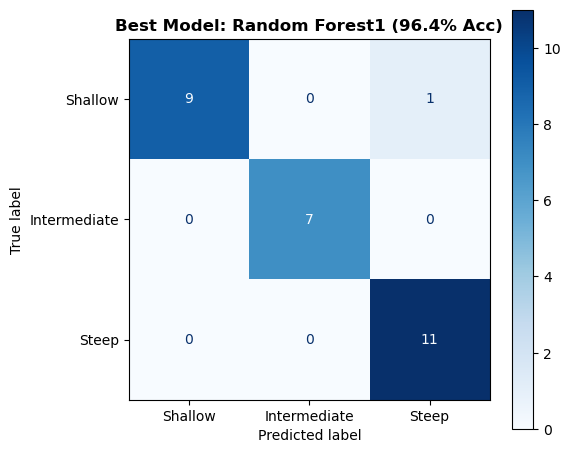

In [18]:
loo = LeaveOneOut()
y_all = df_features['root_class'].values
np.random.seed(42)
print("=== SWEEPING FEATURE SUBSETS & CLASSIFIERS ===")
best_overall_acc = 0.0
best_summary = None

for k in [3,4,5]:
    top_cols = ranking_df['Feature'].head(k).tolist()
    X_mat = df_features[top_cols].values
    
    for model_type, clf in [
        # ('Random Forest3',      RandomForestClassifier(n_estimators=150,max_depth=1,max_features=3, class_weight='balanced', random_state=42)),
        # ('Random Forest2',      RandomForestClassifier(n_estimators=150,max_depth=2,max_features=5, class_weight='balanced', random_state=42)),
        ('Random Forest1',      RandomForestClassifier(n_estimators=150,max_depth=2,max_features=3, class_weight='balanced', random_state=42)),
    ]:
        y_true, y_pred = [], []
        meta = []
        
        for train_idx, test_idx in loo.split(X_mat):
            X_tr, X_te = X_mat[train_idx], X_mat[test_idx]
            y_tr, y_te = y_all[train_idx], y_all[test_idx]
            
            scaler = StandardScaler()
            X_tr_s = scaler.fit_transform(X_tr)
            X_te_s = scaler.transform(X_te)
            
            clf.fit(X_tr_s, y_tr)
            p = clf.predict(X_te_s)[0]
            
            y_pred.append(p)
            y_true.append(y_te[0])
            
            meta.append({
                'Plant': df_features.iloc[test_idx[0]]['plant'],
                'Angle': df_features.iloc[test_idx[0]]['angle_mean'],
                'Actual': y_te[0],
                'Predicted': p
            })
            
        acc = accuracy_score(y_true, y_pred) * 100
        print(f"k={k} | {model_type:<20} -> Accuracy: {acc:.2f}%")
        
        if acc > best_overall_acc:
            best_overall_acc = acc
            best_summary = (k, model_type, top_cols, y_true, y_pred, meta)

k_b, mod_b, cols_b, y_t_b, y_p_b, meta_b = best_summary
print("\n" + "="*70)
print(f"PEAK ACCURACY: {best_overall_acc:.2f}%")
print(f"Best Model: {mod_b} with top {k_b} features")
print(f"Features: {cols_b}")
print("="*70)

print(f"\n--- CLASSIFICATION REPORT ({mod_b}) ---")
print(classification_report(y_t_b, y_p_b, labels=['Shallow', 'Intermediate', 'Steep']))

res_df = pd.DataFrame(meta_b)
misc_df = res_df[res_df['Actual'] != res_df['Predicted']]
print(f"--- MISCLASSIFIED PLANTS ({len(misc_df)} of {len(res_df)}) ---")
print(misc_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_t_b, y_p_b, labels=['Shallow', 'Intermediate', 'Steep'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Shallow', 'Intermediate', 'Steep'])
disp.plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title(f'Best Model: {mod_b} ({best_overall_acc:.1f}% Acc)', fontweight='bold')
ax.grid(False)
plt.tight_layout()
plt.show()

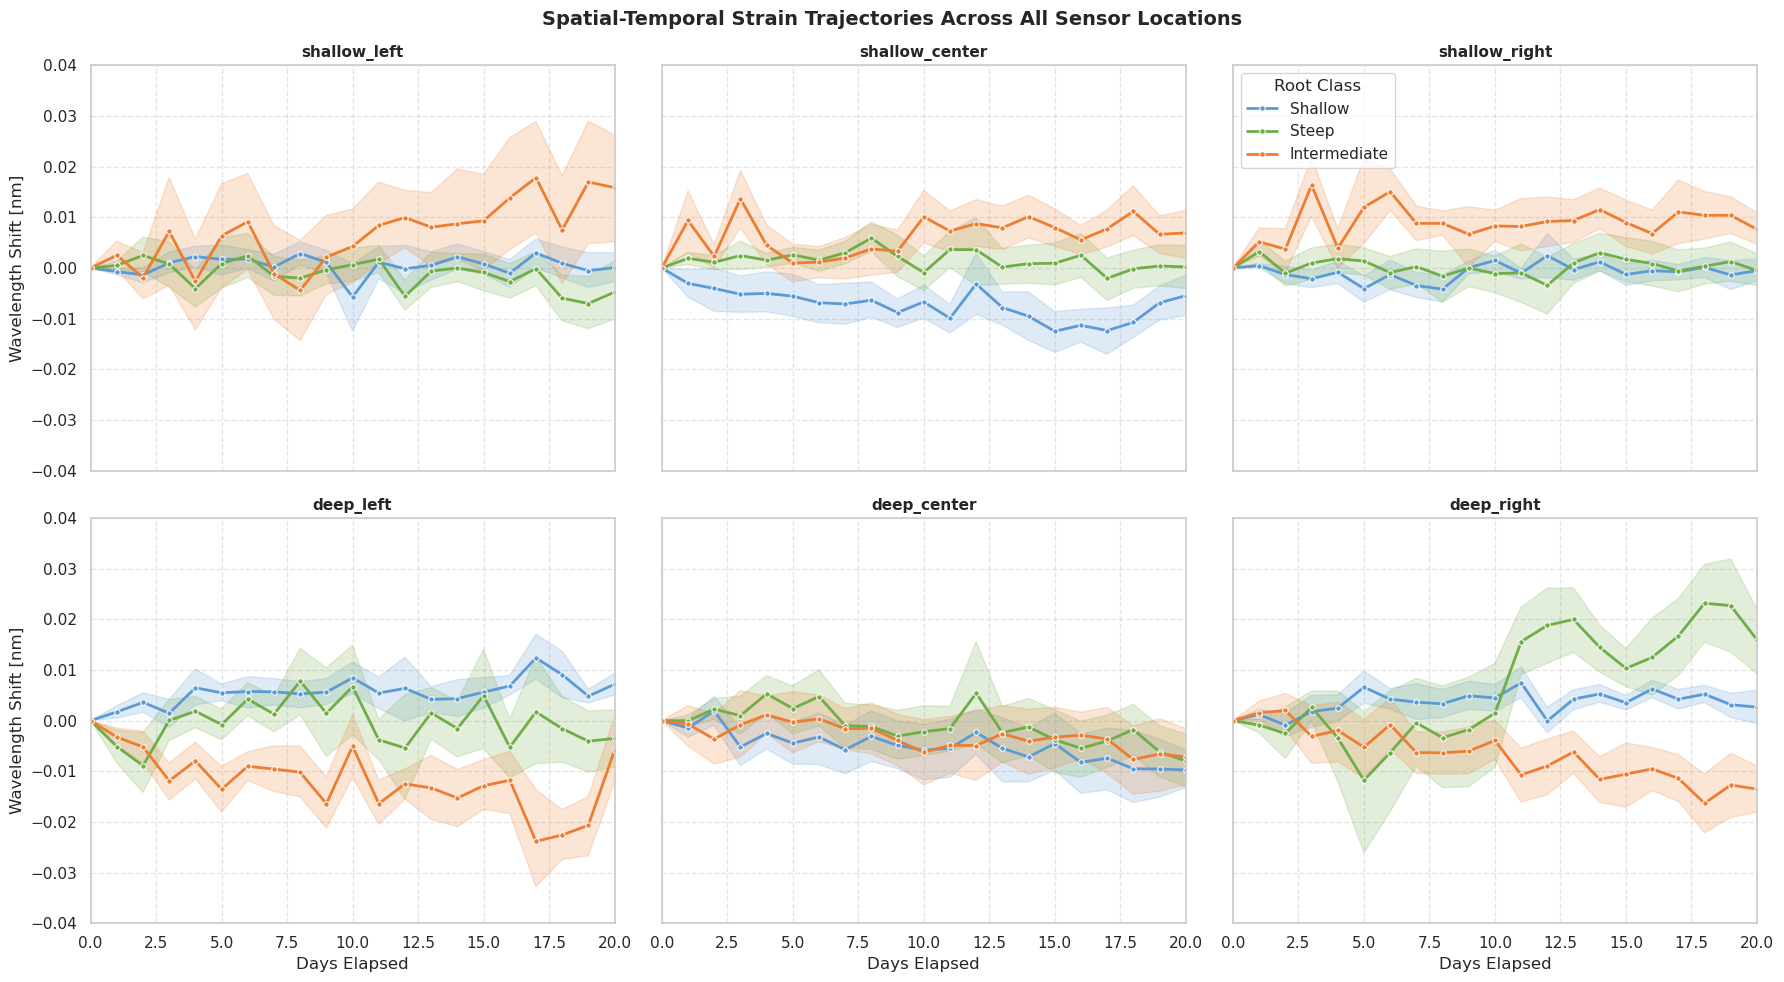

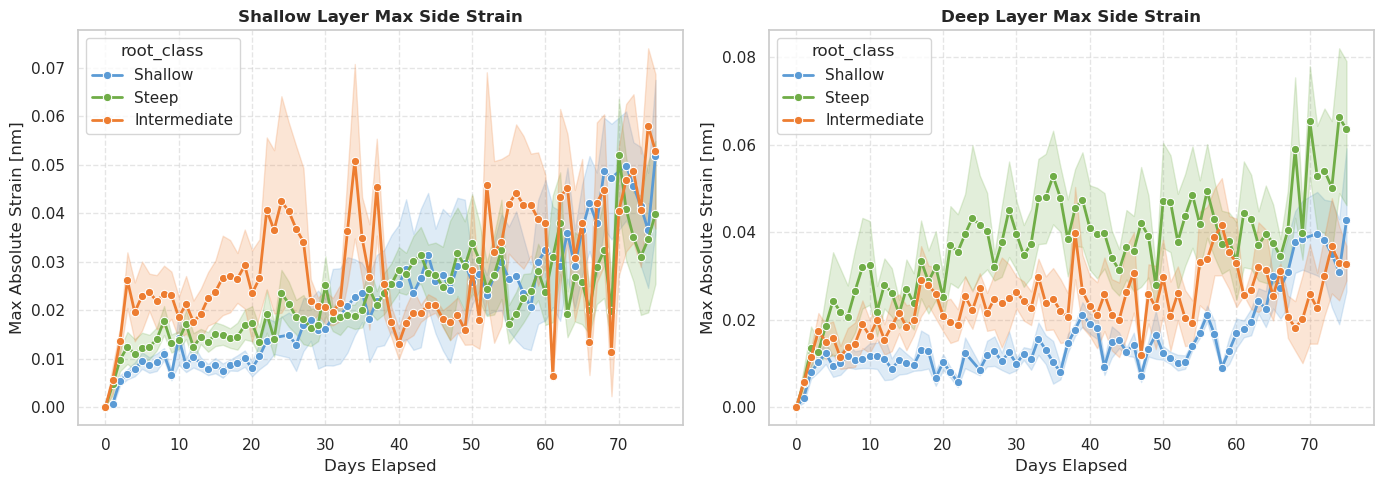

In [21]:
import seaborn as sns

sns.set_theme(style="whitegrid")

def plot_full_spatial_trajectories(plants_feat, plant_df):
    class_map = plant_df.set_index('plant')['root_class'].to_dict()
  
    sensor_grid = [
        ['shallow_left', 'shallow_center', 'shallow_right'],
        ['deep_left',    'deep_center',    'deep_right']
    ]

    records = []
    all_sensors = [col for row in sensor_grid for col in row]
    
    for plant_name, df in plants_feat.items():
        if plant_name not in class_map:
            continue
        r_class = class_map[plant_name]
        for _, row in df.iterrows():
            rec = {'plant': plant_name, 'day': row['day'], 'root_class': r_class}
            for col in all_sensors:
                if col in df.columns:
                    rec[col] = row[col]
            records.append(rec)
            
    ts_df = pd.DataFrame(records)
    
    # Set up 2x3 subplot figure
    fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=True, sharey=True)
    palette = {'Shallow': '#5B9BD5', 'Intermediate': '#ED7D31', 'Steep': '#70AD47'}
    
    for r_idx in range(2):
        for c_idx in range(3):
            sensor_name = sensor_grid[r_idx][c_idx]
            ax = axes[r_idx, c_idx]
            
            if sensor_name in ts_df.columns:
                sns.lineplot(
                    data=ts_df, x='day', y=sensor_name, hue='root_class', palette=palette,
                    ax=ax, marker='o', errorbar=('ci', 68), linewidth=2, markersize=4
                )
            
            # Format individual subplot
            depth_label = "SHALLOW" if r_idx == 0 else "DEEP"
            side_label = ["LEFT", "CENTER", "RIGHT"][c_idx]
            ax.set_title(f"{sensor_name}", fontsize=11, fontweight='bold')
            ax.set_xlabel('Days Elapsed')
            ax.set_ylabel('Wavelength Shift [nm]')
            ax.grid(True, linestyle='--', alpha=0.5)
            ax.set_xlim(0,20)
            ax.set_ylim(-0.04,0.04)
            
            # Keep legend clean (only on top-right plot)
            if r_idx == 0 and c_idx == 2:
                ax.legend(title='Root Class', loc='upper left')
            else:
                if ax.get_legend() is not None:
                    ax.get_legend().remove()
                    
    plt.suptitle("Spatial-Temporal Strain Trajectories Across All Sensor Locations", fontsize=14, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.show()

# Run the 2x3 trajectory grid
plot_full_spatial_trajectories(plants_feat, plant_df)

def plot_side_aggregated_trajectories(plants_feat, plant_df):
    """
    Computes and plots maximum lateral (side) strain for Shallow vs Deep layers
    to account for root orientation asymmetry.
    """
    class_map = plant_df.set_index('plant')['root_class'].to_dict()
    records = []
    
    for plant_name, df in plants_feat.items():
        if plant_name not in class_map:
            continue
        r_class = class_map[plant_name]
        
        for _, row in df.iterrows():
            # Calculate max lateral strain magnitudes
            s_left = abs(row.get('shallow_left', 0))
            s_right = abs(row.get('shallow_right', 0))
            d_left = abs(row.get('deep_left', 0))
            d_right = abs(row.get('deep_right', 0))
            
            records.append({
                'plant': plant_name,
                'day': row['day'],
                'root_class': r_class,
                'shallow_max_side': max(s_left, s_right),
                'deep_max_side': max(d_left, d_right),
            })
            
    ts_df = pd.DataFrame(records)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
    palette = {'Shallow': '#5B9BD5', 'Intermediate': '#ED7D31', 'Steep': '#70AD47'}
    
    for idx, col in enumerate(['shallow_max_side', 'deep_max_side']):
        sns.lineplot(
            data=ts_df, x='day', y=col, hue='root_class', palette=palette,
            ax=axes[idx], marker='o', errorbar=('ci', 68), linewidth=2
        )
        title = "Shallow Layer Max Side Strain" if idx == 0 else "Deep Layer Max Side Strain"
        axes[idx].set_title(title, fontsize=12, fontweight='bold')
        axes[idx].set_xlabel('Days Elapsed')
        axes[idx].set_ylabel('Max Absolute Strain [nm]')
        axes[idx].grid(True, linestyle='--', alpha=0.5)
        
    plt.tight_layout()
    plt.show()

# Run the side-aggregated view
plot_side_aggregated_trajectories(plants_feat, plant_df)